#Complex valued electrical modelling
#in the previous examples we were working with a single point and multiple freq, now we will do spatial fwd model -> simulating field 2D measure with 1 freq and answering the question - model is like this what will be response?

In [2]:
# R = Real (actual R value) + Im (polarization - the ground's ability to temporarily store charge)

In [3]:
import numpy as np
import matplotlib.pylab as plt

import pygimli as pg
import pygimli.meshtools as mt
from pygimli.physics import ert

In [4]:
scheme = ert.createData(
    elecs=np.linspace(start=0, stop=50, num=51),
    schemeName='dd'
)

# 51 electrodes with a spacing of 1m

30/10/26 - 20:33:10 - pyGIMLi - INFO - Save RVector binary
30/10/26 - 20:33:10 - pyGIMLi - INFO - Cache stored: C:\Users\anves\AppData\Roaming\pygimli\Cache\8684358644144939418


(<Axes: xlabel='$x$ in m', ylabel='Depth in m'>, None)

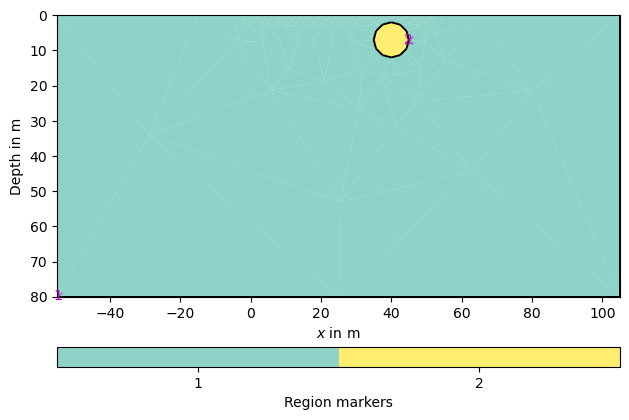

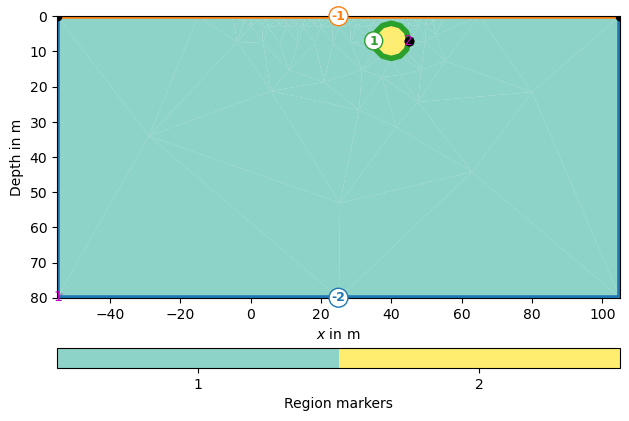

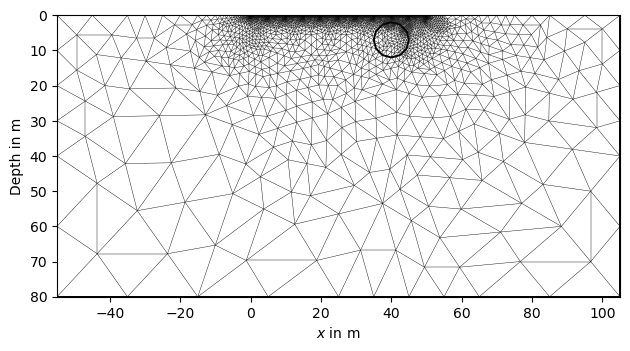

In [5]:
# mesh generation 
world = mt.createWorld(
    start=[-55, 0], end=[105, -80], worldMarker=True)

polarizable_anomaly = mt.createCircle(
    pos=[40, -7], radius=5, marker=2
) # circle

# making the piecewise linear complex
plc = world + polarizable_anomaly

# local refinement of mesh near electrodes
for s in scheme.sensors():
    plc.createNode(s + [0.0, -0.2]) # adding extra node 0.2 m below all electrodes

mesh_coarse = mt.createMesh(plc, quality=33) # triangular voxels
# additional refinements
mesh = mesh_coarse.createH2()

# Create a P2-optimized mesh (quadratic shape functions)
mesh = mesh.createP2() # extra nodes at midpoint of edges 

pg.show(plc, marker=True)
pg.show(plc, markers=True)
pg.show(mesh)

C:\Users\anves\AppData\Local\Temp\ipykernel_34604\4023692632.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


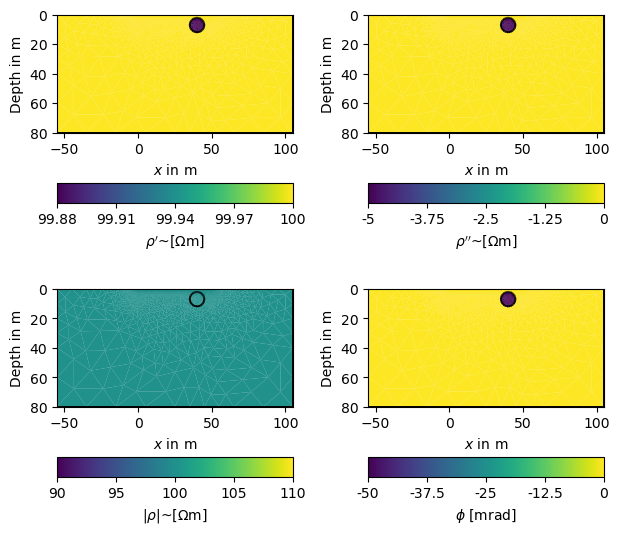

In [6]:
# defines complex R for each region and, maps them on and plots them 
rhomap = [
    [1, pg.utils.complex.toComplex(100, 0 / 1000)], # background
    # Magnitude: 100 ohm m, Phase: -50 mrad
    [2, pg.utils.complex.toComplex(100, -50 / 1000)], # circle
] # marker, value pairs

# For visualization, map the rhomap into the actual mesh, resulting in a rho
# vector with a complex resistivity associated with each mesh cell.
rho = pg.solver.parseArgToArray(rhomap, mesh.cellCount(), mesh)
fig, axes = plt.subplots(2, 2, figsize=(16 / 2.54, 16 / 2.54))
pg.show(mesh, data=np.real(rho), ax=axes[0, 0], label=r"$\rho'$~[$\Omega$m]")
pg.show(mesh, data=np.imag(rho), ax=axes[0, 1], label=r"$\rho''$~[$\Omega$m]")
pg.show(mesh, data=np.abs(rho), ax=axes[1, 0], label=r"$|\rho$|~[$\Omega$m]")
pg.show(
    mesh, data=np.arctan2(np.imag(rho), np.real(rho))*1000,
    ax=axes[1, 1], label=r"$\phi$ [mrad]"
)
fig.tight_layout()
fig.show()

In [7]:
# actual fwd modelling
data = ert.simulate(
    mesh,
    res=rhomap,
    scheme=scheme,
    # noiseAbs=0.0,
    # noiseLevel=0.0,
)

30/10/26 - 20:39:20 - pyGIMLi - INFO - Complex resistivity values found.


C:\Users\anves\AppData\Local\Temp\ipykernel_34604\1786882809.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


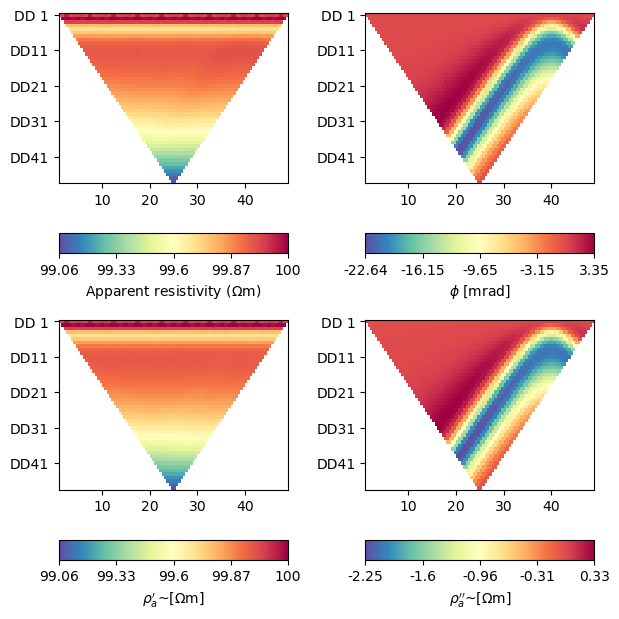

In [8]:
# visualise data and find complex Z and phi values 
rho_a_complex = data['rhoa'].array() * np.exp(1j * data['phia'].array())

fig, axes = plt.subplots(2, 2, figsize=(16 / 2.54, 16 / 2.54))
ert.showERTData(data, vals=data['rhoa'], ax=axes[0, 0])

ert.showERTData(
    data, vals=data['phia'] * 1000, label=r'$\phi$ [mrad]', ax=axes[0, 1])

ert.showERTData(
    data, vals=np.real(rho_a_complex), ax=axes[1, 0],
    label=r"$\rho_a'$~[$\Omega$m]"
)
ert.showERTData(
    data, vals=np.imag(rho_a_complex), ax=axes[1, 1],
    label=r"$\rho_a''$~[$\Omega$m]"
)
fig.tight_layout()
fig.show()